<a href="https://colab.research.google.com/github/hsb-ctrl-zy/multi-team1-project/blob/main/%EC%BD%94%EB%9E%A9/%EB%B8%8C%EB%9E%9C%EB%93%9C%EB%B3%84_%EC%83%81%ED%92%88_%EB%AA%85%EC%82%AC.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 브래드별 상품명의 명사 개수

### 필요 라이브러리 설치 및 로드

In [ ]:
!pip install pymysql

In [ ]:
import pymysql

### SQL 연결

In [ ]:
#데이터베이스 연결
conn=pymysql.connect(
    host=host_name,
    user=user_name,
    password=password_val,
    database=db_name,
    port=port_num,
    charset='utf8'
)

### MySQL 연결 상태 확인

In [ ]:
if conn:
    try:
        # 커서를 생성하여 쿼리 실행 준비
        with conn.cursor() as cursor:
            # 간단한 쿼리로 현재 연결된 데이터베이스 이름을 확인
            cursor.execute("SELECT DATABASE();")
            result = cursor.fetchone()
            if result and result[0]:
                print(f"데이터베이스 연결이 성공적으로 확인되었습니다. 현재 데이터베이스: {result[0]}")
            else:
                print("데이터베이스에 연결되었지만, 현재 데이터베이스 이름을 가져올 수 없습니다.")
    except pymysql.Error as e:
        print(f"데이터베이스 연결 확인 중 오류 발생: {e}")
        print("연결에 문제가 있을 수 있습니다.")
else:
    print("데이터베이스 연결 객체(conn)가 생성되지 않았습니다. 연결이 실패했을 수 있습니다.")

데이터베이스 연결이 성공적으로 확인되었습니다. 현재 데이터베이스: geo_db


## 형태소 분석을 위한 라이브러리 설치 및 준비

In [ ]:
# konlpy 설치
!pip install konlpy
!pip install kiwipiepy

## 필요한 라이브러리 임포트 및 형태소 분석기 초기화

In [ ]:
import pandas as pd
from konlpy.tag import Okt, Kkma, Komoran
from kiwipiepy import Kiwi

# 형태소 분석기 초기화
okt = Okt()
kkma = Kkma()
komoran = Komoran()
kiwi = Kiwi()

print("형태소 분석기 초기화 완료: Okt, Kkma, Komoran, Kiwi")

형태소 분석기 초기화 완료: Okt, Kkma, Komoran, Kiwi


## `geo_db`에서 `raw_data_table` 데이터 로드

In [ ]:
try:
    # 커서를 생성하여 쿼리 실행 준비
    with conn.cursor(pymysql.cursors.DictCursor) as cursor:
        sql_query = "SELECT brand_name, text_contents FROM raw_data_table"
        cursor.execute(sql_query)
        data = cursor.fetchall()
        df = pd.DataFrame(data)
    print("데이터 로드 성공")
    display(df.head(10))
except pymysql.Error as e:
    print(f"데이터 로드 중 오류 발생: {e}")
    df = pd.DataFrame()

# 데이터가 비어있을 경우를 대비
if df.empty:
    print("데이터프레임이 비어있습니다. 데이터를 가져오지 못했거나 테이블에 데이터가 없습니다.")
else:
    # 결측치 확인 및 제거 (text_contents에 결측치가 있으면 분석에 오류 발생 가능)
    initial_rows = len(df)
    df.dropna(subset=['text_contents'], inplace=True)
    removed_rows = initial_rows - len(df)
    if removed_rows > 0:
        print(f"{removed_rows}개의 결측치(text_contents가 없는 행)를 제거했습니다.")
    print(f"최종 데이터프레임 크기: {len(df)} 행")

데이터 로드 성공


,brand_name,text_contents
0,CJ,
1,CJ,[엔비에이][NBA] 스몰로고 트레이닝 반바지(N262TP942P)\n시그니처 로고...
2,CJ,
3,CJ,
4,CJ,
5,CJ,
6,CJ,
7,CJ,다크카키(DKS)\n민트(MTS)\n스카이블루(SBL)\n다크그레이(GRD)\n블랙...
8,CJ,？？？？？？？
9,CJ,


최종 데이터프레임 크기: 8763 행


## 형태소 분석 및 명사 개수 계산

In [ ]:
def count_nouns(text, tagger):
    if not isinstance(text, str):
        return []
    try:
        if tagger == okt:
            return [word for word, tag in okt.pos(text) if tag in ['Noun', 'Foreign']]
        elif tagger == kkma:
            return [word for word, tag in kkma.pos(text) if 'N' in tag or 'F' in tag]
        elif tagger == komoran:
            return [word for word, tag in komoran.pos(text) if tag in ['NNG', 'NNP', 'NP', 'NR', 'SL']]
        elif tagger == kiwi:
            return [token.form for token in kiwi.tokenize(text) if token.tag.startswith('N')]
        else:
            return []
    except Exception as e:
        print(f"형태소 분석 중 오류 발생 ({tagger.__class__.__name__}): {e} - 텍스트: {text[:50]}...")
        return []

# 각 형태소 분석기로 명사 추출 및 개수 계산
df['okt_nouns'] = df['text_contents'].apply(lambda x: count_nouns(x, okt))
df['okt_noun_count'] = df['okt_nouns'].apply(len)

df['kkma_nouns'] = df['text_contents'].apply(lambda x: count_nouns(x, kkma))
df['kkma_noun_count'] = df['kkma_nouns'].apply(len)

df['komoran_nouns'] = df['text_contents'].apply(lambda x: count_nouns(x, komoran))
df['komoran_noun_count'] = df['komoran_nouns'].apply(len)

df['kiwi_nouns'] = df['text_contents'].apply(lambda x: count_nouns(x, kiwi))
df['kiwi_noun_count'] = df['kiwi_nouns'].apply(len)

display(df[['brand_name', 'text_contents', 'okt_noun_count', 'kkma_noun_count', 'komoran_noun_count']].head())

,brand_name,text_contents,okt_noun_count,kkma_noun_count,komoran_noun_count
0,CJ,,0,0,0
1,CJ,[엔비에이][NBA] 스몰로고 트레이닝 반바지(N262TP942P)\n시그니처 로고...,217,230,217
2,CJ,,0,0,0
3,CJ,,0,0,0
4,CJ,,0,0,0


## 브랜드별 명사 개수 분석 결과


In [ ]:
brand_noun_analysis = df.groupby('brand_name')[['okt_noun_count', 'kkma_noun_count', 'komoran_noun_count','kiwi_noun_count']].mean().reset_index()

print("브랜드별 평균 명사 개수:")
display(brand_noun_analysis.sort_values(by='okt_noun_count', ascending=False))

브랜드별 평균 명사 개수:


,brand_name,okt_noun_count,kkma_noun_count,komoran_noun_count,kiwi_noun_count
8,메리엣,232.346154,244.923077,171.769231,165.653846
17,자스민벨,218.871429,215.839286,137.882143,127.921429
16,올라,157.280000,156.336000,130.656000,122.392000
18,홀리,105.232044,104.839779,82.519337,78.618785
9,미니포에,98.160000,108.230000,81.530000,83.420000
12,슈가파우더,75.838196,74.636605,58.124668,55.718833
3,Uniqlo,65.044289,74.685315,72.307692,56.093240
6,루프온,55.202128,52.755319,46.595745,35.578014
2,LF,51.202612,60.089830,48.863079,41.786308
1,CJ,18.426271,19.965283,15.403364,14.525770


In [ ]:
# # 나눔고딕 폰트 설치 (사용자 지정 Pretendard 폰트 사용을 위해 주석 처리합니다)
# !sudo apt-get install -y fonts-nanum
# !sudo fc-cache -fv
# !rm -rf ~/.cache/matplotlib

In [ ]:
from google.colab import files
files.upload()

In [ ]:
import os
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

# 마이너스 기호 깨짐 방지
plt.rcParams['axes.unicode_minus'] = False

# --- 사용자 제공 폰트 설정 ---
font_path = '/content/Pretendard－M.ttf'

if os.path.exists(font_path):
    fm.fontManager.addfont(font_path)
    font_prop = fm.FontProperties(fname=font_path)
    font_name = font_prop.get_name()
    plt.rc('font', family=font_name)
    print(f"'{font_name}' 폰트 설정 완료.")
else:
    print(f"경로에 '{font_path}' 폰트 파일을 찾을 수 없습니다. 기본 폰트(나눔고딕 또는 대체 폰트)를 사용합니다.")
    try:
        fm.findfont('NanumGothic', rebuild_if_missing=True)
        plt.rc('font', family='NanumGothic')
        print("NanumGothic 폰트가 설치되어 있어 이를 사용합니다.")
    except Exception:
        plt.rc('font', family='DejaVu Sans')
        print("기본 폰트를 찾을 수 없어 'DejaVu Sans'를 사용합니다.")

# 모든 텍스트 및 축 요소 색상을 흰색으로 설정
plt.rcParams['text.color'] = 'white'
plt.rcParams['axes.labelcolor'] = 'white'
plt.rcParams['xtick.color'] = 'white'
plt.rcParams['ytick.color'] = 'white'
plt.rcParams['axes.edgecolor'] = 'white'
plt.rcParams['figure.facecolor'] = 'none'
plt.rcParams['savefig.facecolor'] = 'none'
plt.rcParams['axes.facecolor'] = 'none'

print("Matplotlib 한글 폰트 및 디자인 설정 완료 (Pretendard 폰트 파일을 업로드해야 제대로 적용됩니다).")

'Pretendard' 폰트 설정 완료.
Matplotlib 한글 폰트 및 디자인 설정 완료 (Pretendard 폰트 파일을 업로드해야 제대로 적용됩니다).


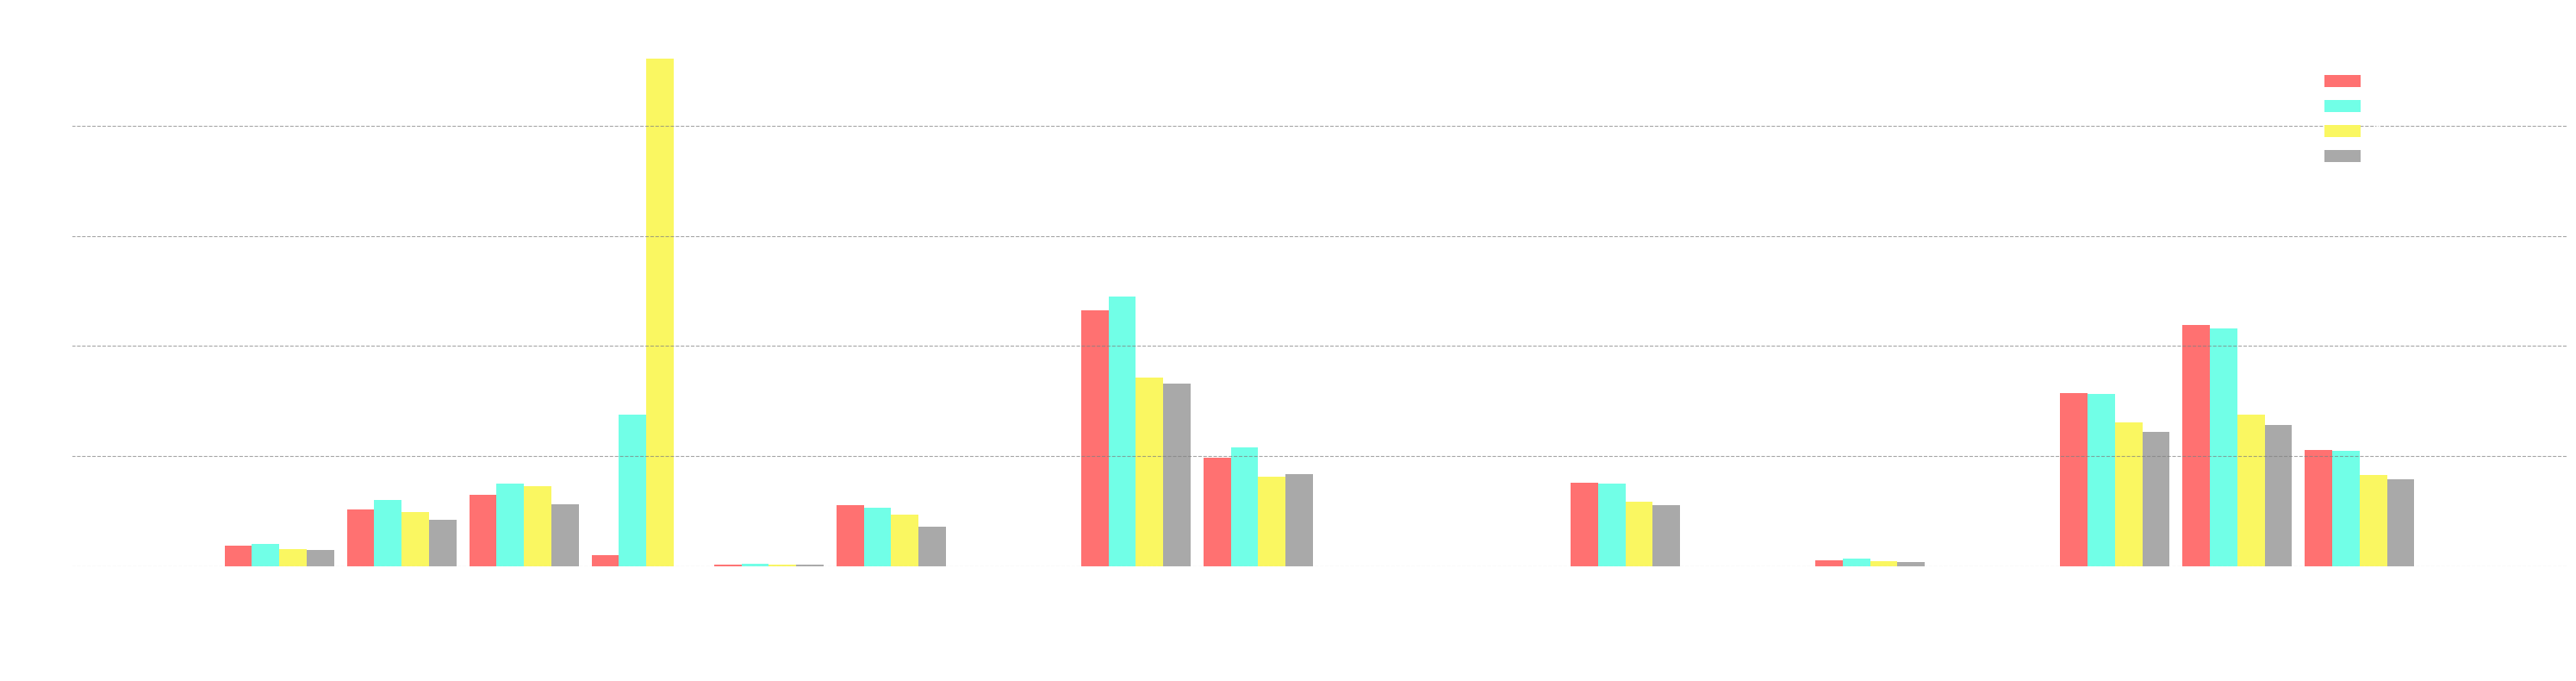

In [ ]:
# Custom color palette
custom_palette = ['#FF7171', '#71FFE7', '#FAF761', '#A9A9A9']

# 시각화
fig, ax = plt.subplots(figsize=(30, 8))

# 배경 투명 설정
fig.patch.set_alpha(0)
ax.set_facecolor('none')

# 데이터프레임을 복사하여 'brand_name'을 인덱스로 설정하고 플롯
plot_data = brand_noun_analysis.set_index('brand_name')

# 형태소 분석기별 색상 매핑
colors_map = {
    'okt_noun_count': '#FF7171',
    'kkma_noun_count': '#71FFE7',
    'komoran_noun_count': '#FAF761',
    'kiwi_noun_count': '#A9A9A9'
}
# 플롯할 컬럼 순서에 맞춰 색상 리스트 생성
plot_colors = [colors_map[col] for col in plot_data.columns if col in colors_map]

# Bar plot
plot_data.plot(kind='bar', ax=ax, color=plot_colors, width=0.9)

plt.title('브랜드별 평균 명사 개수 (형태소 분석기별)', fontsize=20, color='white')
plt.xlabel('브랜드 이름', fontsize=15, color='white')
plt.ylabel('평균 명사 개수', fontsize=15, color='white')
plt.xticks(rotation=45, ha='right', fontsize=15, color='white')
plt.yticks(fontsize=15, color='white')

# 범례 설정 (배경 투명, 테두리 없음)
legend = plt.legend(title='형태소 분석기', title_fontsize='15', fontsize='15', facecolor='none', edgecolor='none')
# 범례 텍스트 색상 변경
for text in legend.get_texts():
    text.set_color('white')
# 범례 제목 색상 변경
legend.get_title().set_color('white')


plt.grid(axis='y', linestyle='--', alpha=0.7, color='gray')
plt.tight_layout()

# 차트에 값 수치 표시
for container in ax.containers:
    ax.bar_label(container, fmt='%.1f', label_type='edge', color='white', fontsize=9)

plt.savefig('브랜드별_명사_수.png')
plt.show()